# 🖼️ Notebook 03 — Image Preprocessing

**Phase 4 of the project**

For every image in the dataset:
```
Original Image (700x460 color PNG)
       ↓
Read with OpenCV
       ↓
Convert to Grayscale
       ↓
Resize to 224x224
       ↓
Normalize to [0, 1]
       ↓
Ready for GLCM / LBP extraction
```

We also visually verify the preprocessing looks correct.

**Run each cell with Shift+Enter**

## 0. Setup & Imports

In [1]:
import sys
sys.path.insert(0, r'D:\Projects\ML')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from src.config import METADATA_CSV, FIGURES_DIR, IMAGE_SIZE
from src.preprocessing import ImagePreprocessor
from src.utils import set_plot_style, save_figure

set_plot_style()
prep = ImagePreprocessor(image_size=IMAGE_SIZE)

metadata = pd.read_csv(METADATA_CSV)
print('Preprocessing target size:', IMAGE_SIZE)
print('Total images to process:', len(metadata))

Preprocessing target size: (224, 224)
Total images to process: 7909


## 1. Test Preprocessing on One Image

In [2]:
# Pick one benign and one malignant sample
sample_benign    = metadata[metadata['class_name']=='benign'].iloc[0]['image_path']
sample_malignant = metadata[metadata['class_name']=='malignant'].iloc[0]['image_path']

print('Sample benign path   :', sample_benign)
print('Sample malignant path:', sample_malignant)

Sample benign path   : D:\Projects\ML\dataset\BreaKHis_v1\histology_slides\breast\benign\SOB\adenosis\SOB_B_A_14-22549AB\100X\SOB_B_A-14-22549AB-100-001.png
Sample malignant path: D:\Projects\ML\dataset\BreaKHis_v1\histology_slides\breast\malignant\SOB\ductal_carcinoma\SOB_M_DC_14-10926\100X\SOB_M_DC-14-10926-100-001.png


📊  Saved figure → D:\Projects\ML\outputs\figures\03_preprocessing_pipeline.png


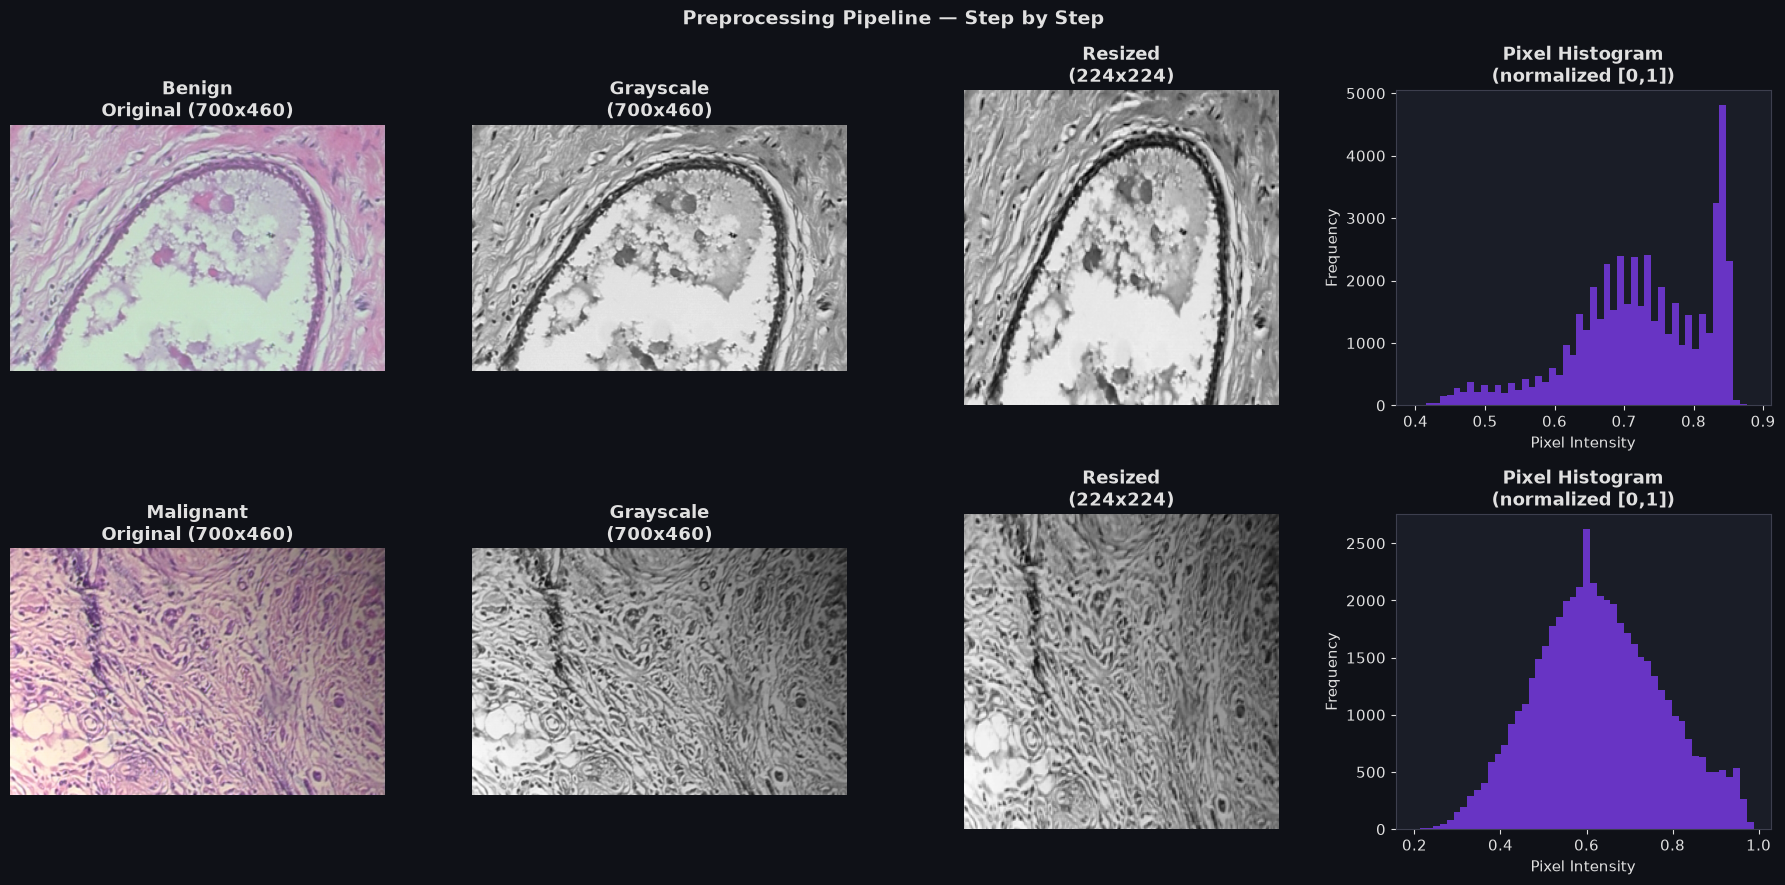

Original shape : (460, 700, 3)
After preprocess: (224, 224) | dtype: float32
Pixel range     : 0.196 to 0.988


In [3]:
# Show step-by-step preprocessing pipeline
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Preprocessing Pipeline — Step by Step', fontsize=14)

for row, (path, label) in enumerate([(sample_benign,'Benign'), (sample_malignant,'Malignant')]):
    # Step 1: Original
    original = cv2.imread(path)
    original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    axes[row,0].imshow(original_rgb)
    axes[row,0].set_title(f'{label}\nOriginal ({original.shape[1]}x{original.shape[0]})')
    axes[row,0].axis('off')

    # Step 2: Grayscale
    gray = cv2.cvtColor(original, cv2.COLOR_BGR2GRAY)
    axes[row,1].imshow(gray, cmap='gray')
    axes[row,1].set_title(f'Grayscale\n({gray.shape[1]}x{gray.shape[0]})')
    axes[row,1].axis('off')

    # Step 3: Resized
    resized = cv2.resize(gray, (IMAGE_SIZE[1], IMAGE_SIZE[0]), interpolation=cv2.INTER_AREA)
    axes[row,2].imshow(resized, cmap='gray')
    axes[row,2].set_title(f'Resized\n({IMAGE_SIZE[1]}x{IMAGE_SIZE[0]})')
    axes[row,2].axis('off')

    # Step 4: Normalized + histogram
    normalized = resized.astype(np.float32) / 255.0
    axes[row,3].hist(normalized.ravel(), bins=50, color='#7c3aed', alpha=0.8)
    axes[row,3].set_title(f'Pixel Histogram\n(normalized [0,1])')
    axes[row,3].set_xlabel('Pixel Intensity')
    axes[row,3].set_ylabel('Frequency')

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '03_preprocessing_pipeline.png')
plt.show()

print('Original shape :', original.shape)
print('After preprocess:', normalized.shape, '| dtype:', normalized.dtype)
print('Pixel range     :', normalized.min().round(3), 'to', normalized.max().round(3))

## 2. Verify Preprocessing Class for Full Pipeline

In [4]:
# Test the ImagePreprocessor class used in feature extraction
img_float  = prep.preprocess(sample_benign)          # float [0,1] for LBP
img_uint8  = prep.preprocess_to_uint8(sample_benign)  # uint8 for GLCM

print('Float preprocessed  (for LBP) :', img_float.shape, img_float.dtype,
      f'range=[{img_float.min():.3f}, {img_float.max():.3f}]')
print('Uint8 preprocessed  (for GLCM):', img_uint8.shape, img_uint8.dtype,
      f'range=[{img_uint8.min()}, {img_uint8.max()}]')
print()
print('Preprocessing class works correctly!')

Float preprocessed  (for LBP) : (224, 224) float32 range=[0.129, 0.965]
Uint8 preprocessed  (for GLCM): (224, 224) uint8 range=[33, 246]

Preprocessing class works correctly!


## 3. Spot-Check Random Images

📊  Saved figure → D:\Projects\ML\outputs\figures\03_preprocessed_samples.png


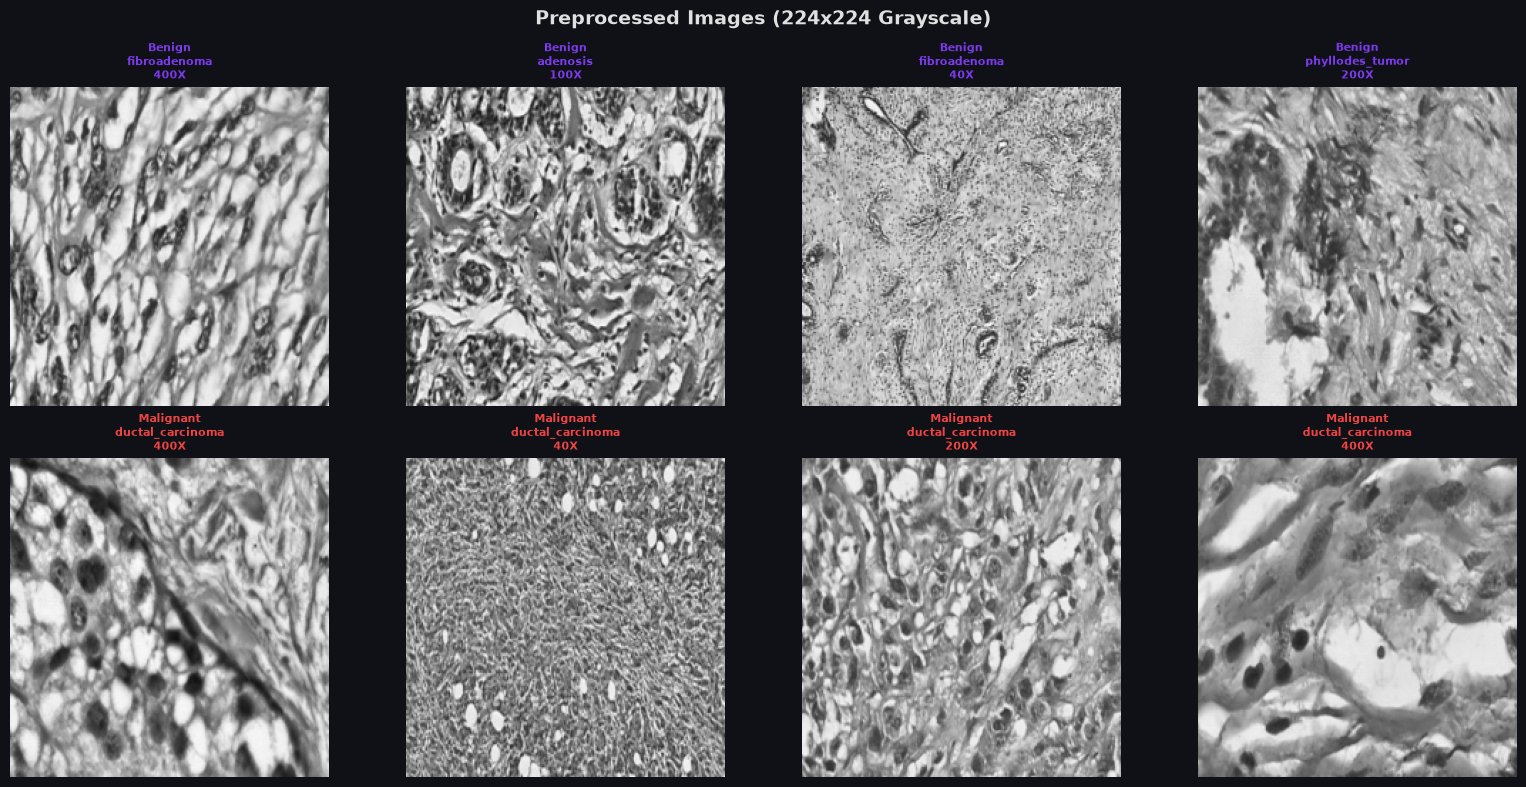

In [5]:
# Show 8 preprocessed images (4 benign + 4 malignant)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Preprocessed Images (224x224 Grayscale)', fontsize=14)

for row, cls in enumerate(['benign','malignant']):
    samples = metadata[metadata['class_name']==cls].sample(4, random_state=42)
    for col, (_, rec) in enumerate(samples.iterrows()):
        img = prep.preprocess(rec['image_path'])
        axes[row, col].imshow(img, cmap='gray', vmin=0, vmax=1)
        axes[row, col].set_title(
            f"{cls.capitalize()}\n{rec['subtype']}\n{rec['magnification']}",
            fontsize=8,
            color='#ef4444' if cls=='malignant' else '#7c3aed'
        )
        axes[row, col].axis('off')

plt.tight_layout()
save_figure(fig, FIGURES_DIR / '03_preprocessed_samples.png')
plt.show()

## 4. Summary

In [6]:
print('='*55)
print('  PHASE 4 COMPLETE - Image Preprocessing')
print('='*55)
print(f'  Pipeline: BGR -> Grayscale -> {IMAGE_SIZE} -> [0,1]')
print(f'  For GLCM: uint8 output (0-255)')
print(f'  For LBP : float32 output (0.0-1.0)')
print(f'  Total images ready: {len(metadata):,}')
print()
print('  Next: Notebook 04 - GLCM Feature Extraction')
print('='*55)

  PHASE 4 COMPLETE - Image Preprocessing
  Pipeline: BGR -> Grayscale -> (224, 224) -> [0,1]
  For GLCM: uint8 output (0-255)
  For LBP : float32 output (0.0-1.0)
  Total images ready: 7,909

  Next: Notebook 04 - GLCM Feature Extraction
